<a href="https://colab.research.google.com/github/tasnimfarhat27/Customer-Churn-Prediction/blob/main/Customer_Churn_Prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
# Cell 1: Mount Google Drive and install libraries
!pip install xgboost lightgbm shap -q

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from google.colab import drive
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, confusion_matrix,
    ConfusionMatrixDisplay, roc_curve
)

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

import shap

# Mount Drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [3]:
# Cell 2: Load the dataset using your Google Drive folder path
file_path = '/content/drive/MyDrive/Cutomer Churn Prediction/WA_Fn-UseC_-Telco-Customer-Churn.csv'

df = pd.read_csv(file_path)
print("✓ Dataset successfully loaded from Google Drive!")
print(f"Dataset Shape: {df.shape}")
df.head()

✓ Dataset successfully loaded from Google Drive!
Dataset Shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [4]:
# Cell 3: Data Cleaning & Feature Preprocessing Setup

# 1. Clean whitespace strings in TotalCharges and cast to float
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'].str.strip(), errors='coerce').fillna(0)

# 2. Encode Target variable (Yes = 1, No = 0)
df['Churn'] = df['Churn'].map({'Yes': 1, 'No': 0})

# 3. Separate features (X) and target (y), dropping customerID
X = df.drop(columns=['customerID', 'Churn'])
y = df['Churn']

# 4. Stratified Train-Test Split (80% Train, 20% Test)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

# 5. Build ColumnTransformer for numerical scaling and categorical encoding
num_cols = ['tenure', 'MonthlyCharges', 'TotalCharges']
cat_cols = [col for col in X.columns if col not in num_cols]

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_cols),
        ('cat', OneHotEncoder(drop='first', sparse_output=False), cat_cols)
    ]
)

# 6. Fit preprocessor on training data and transform both sets
X_train_proc = preprocessor.fit_transform(X_train)
X_test_proc = preprocessor.transform(X_test)
feature_names = preprocessor.get_feature_names_out()

print(f"✓ Processed Training Matrix Shape: {X_train_proc.shape}")
print(f"✓ Processed Testing Matrix Shape:  {X_test_proc.shape}")

✓ Processed Training Matrix Shape: (5634, 30)
✓ Processed Testing Matrix Shape:  (1409, 30)


In [5]:
# Cell 4: Model Training

# Calculate class ratio for imbalance handling in boosting algorithms
scale_pos_ratio = (len(y_train) - sum(y_train)) / sum(y_train)

models = {
    "Logistic Regression": LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42),
    "K-Nearest Neighbors": KNeighborsClassifier(n_neighbors=5, weights='distance'),
    "Decision Tree": DecisionTreeClassifier(class_weight='balanced', max_depth=5, random_state=42),
    "Random Forest": RandomForestClassifier(class_weight='balanced', n_estimators=100, max_depth=8, random_state=42),
    "XGBoost": XGBClassifier(scale_pos_weight=scale_pos_ratio, n_estimators=100, max_depth=4, learning_rate=0.05, random_state=42, eval_metric='logloss'),
    "LightGBM": LGBMClassifier(scale_pos_weight=scale_pos_ratio, n_estimators=100, max_depth=5, learning_rate=0.05, random_state=42, verbose=-1)
}

trained_models = {}
for name, model in models.items():
    model.fit(X_train_proc, y_train)
    trained_models[name] = model
    print(f"✓ Trained: {name}")

✓ Trained: Logistic Regression
✓ Trained: K-Nearest Neighbors
✓ Trained: Decision Tree
✓ Trained: Random Forest
✓ Trained: XGBoost
✓ Trained: LightGBM


In [6]:
# Cell 5: Benchmark Dataframe Generation
results = []

for name, model in trained_models.items():
    y_pred = model.predict(X_test_proc)
    y_prob = model.predict_proba(X_test_proc)[:, 1]

    results.append({
        "Model": name,
        "Accuracy": round(accuracy_score(y_test, y_pred), 4),
        "Precision": round(precision_score(y_test, y_pred), 4),
        "Recall": round(recall_score(y_test, y_pred), 4),
        "F1-Score": round(f1_score(y_test, y_pred), 4),
        "ROC-AUC": round(roc_auc_score(y_test, y_prob), 4)
    })

comparison_df = pd.DataFrame(results).sort_values(by="ROC-AUC", ascending=False).reset_index(drop=True)
comparison_df

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,XGBoost,0.7480,0.5161,0.8128,0.6314,0.8440
1,Random Forest,0.7594,0.5318,0.7834,0.6335,0.8432
2,LightGBM,0.7509,0.5200,0.7995,0.6301,0.8419
3,Logistic Regression,0.7381,0.5043,0.7834,0.6136,0.8417
4,Decision Tree,0.7346,0.5000,0.8075,0.6176,0.8308
5,K-Nearest Neighbors,0.7580,0.5447,0.5374,0.5410,0.7795


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


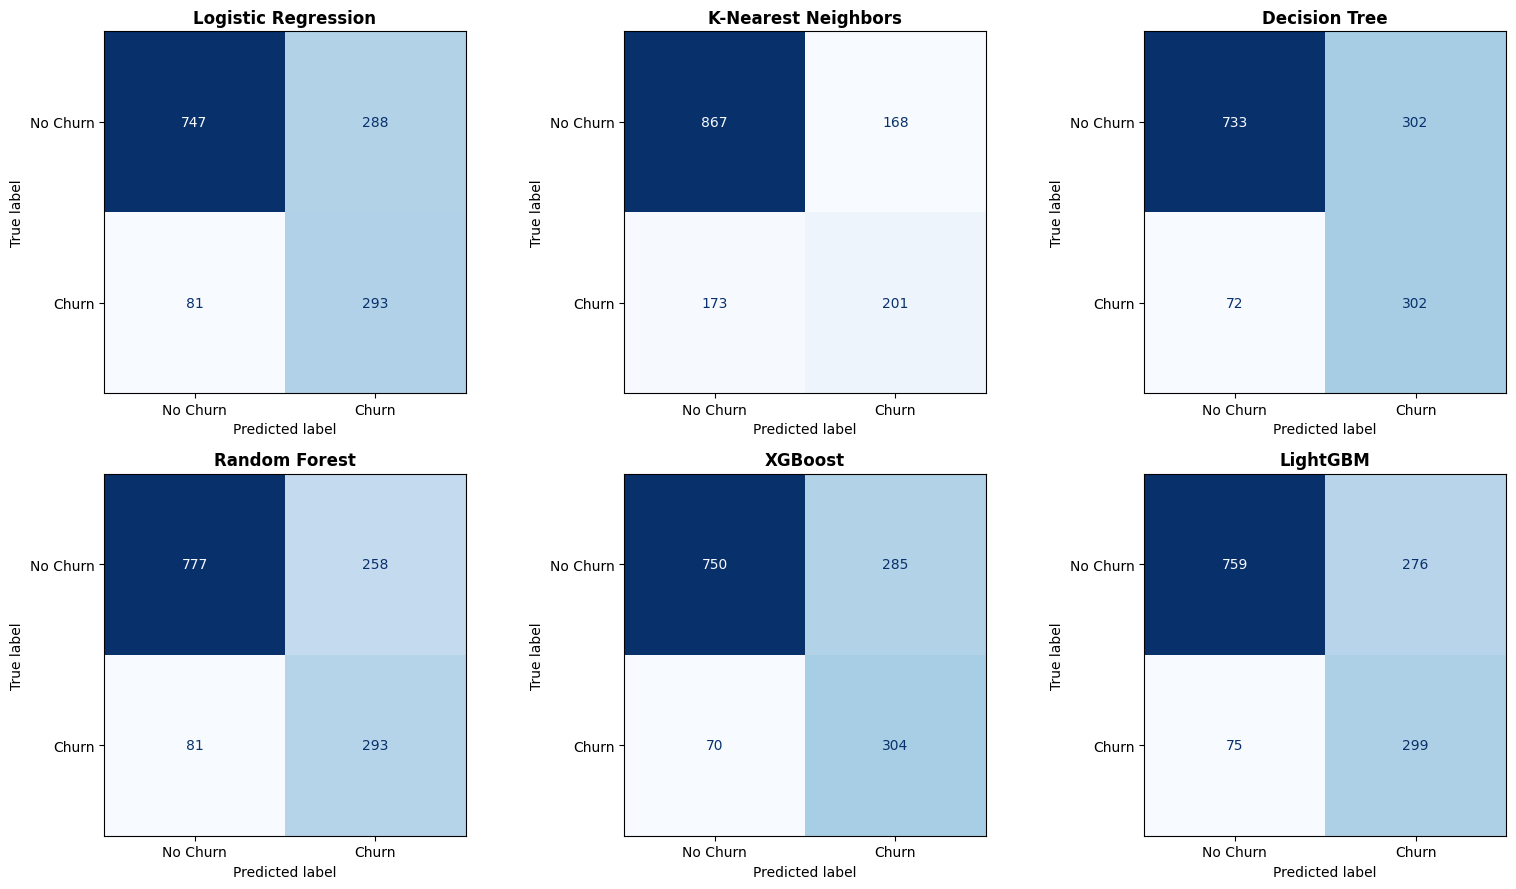

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


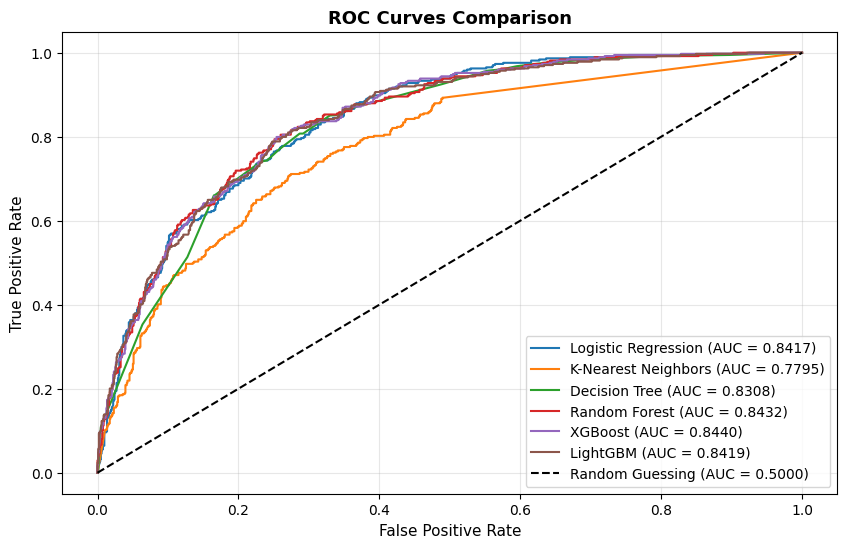

In [8]:
# Cell 6: Visualizations (Confusion Matrices & ROC Overlay)

# 1. Confusion Matrices Grid
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()

for idx, (name, model) in enumerate(trained_models.items()):
    y_pred = model.predict(X_test_proc)
    cm = confusion_matrix(y_test, y_pred)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["No Churn", "Churn"])
    disp.plot(ax=axes[idx], cmap='Blues', colorbar=False)
    axes[idx].set_title(name, fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()

# 2. Comparative ROC Curves Overlay
plt.figure(figsize=(10, 6))
for name, model in trained_models.items():
    y_prob = model.predict_proba(X_test_proc)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    auc_score = roc_auc_score(y_test, y_prob)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {auc_score:.4f})")

plt.plot([0, 1], [0, 1], 'k--', label="Random Guessing (AUC = 0.5000)")
plt.xlabel("False Positive Rate", fontsize=11)
plt.ylabel("True Positive Rate", fontsize=11)
plt.title("ROC Curves Comparison", fontsize=13, fontweight='bold')
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.show()

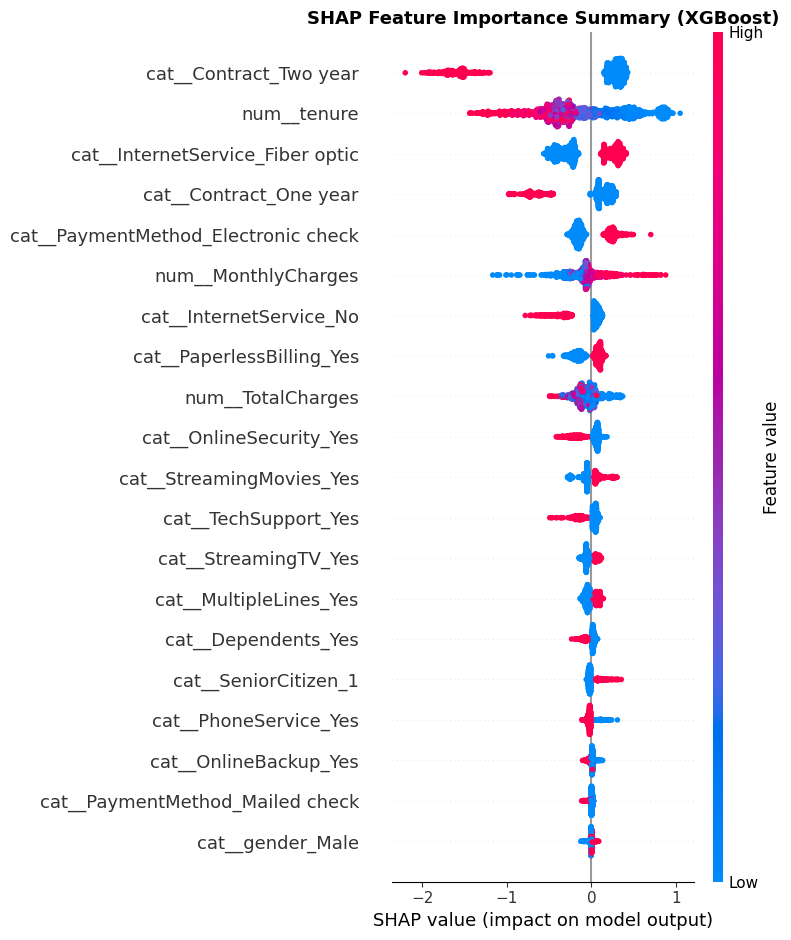

In [9]:
# Cell 7: SHAP Summary Plot
xgb_model = trained_models["XGBoost"]

explainer = shap.TreeExplainer(xgb_model)
shap_values = explainer.shap_values(X_test_proc)

plt.figure(figsize=(10, 6))
shap.summary_plot(shap_values, X_test_proc, feature_names=feature_names, show=False)
plt.title("SHAP Feature Importance Summary (XGBoost)", fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

In [10]:
# Cell 8: Save trained model pipeline directly to your Drive folder
from sklearn.pipeline import Pipeline

production_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('model', trained_models['XGBoost'])
])

save_path = '/content/drive/MyDrive/Cutomer Churn Prediction/telco_churn_pipeline.pkl'
joblib.dump(production_pipeline, save_path)

print(f"✓ Production pipeline saved successfully to Drive: {save_path}")

✓ Production pipeline saved successfully to Drive: /content/drive/MyDrive/Cutomer Churn Prediction/telco_churn_pipeline.pkl
